## CUSTOMER CHURN PREDICTION 

In [1]:
# IMPORTING THE NECESSARY LIBRARIES 

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## LOADING THE DATASET 

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## UNDERSTANDING THE DATASET

In [4]:
# understanding the first five row of data from dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# checking the column in the dataset 
df.shape

(7043, 21)

In [6]:
# checking the summary statistics of dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# information of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
# checking the null value in the dataset
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# checking the num of customer left in the company and stayed in the company 
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
# checking the number of customer leving the company 
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 26.54%


In [11]:
#checking the percentage of customer churn
df["Churn"].value_counts(normalize = True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [12]:
# Visualizing the dataset

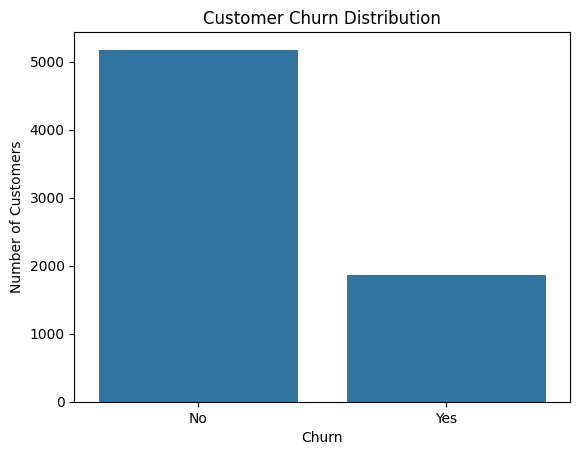

In [13]:
sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

## DATA CLEANING AND EXPLORATORY DATA ANALYSIS

In [14]:
# CHECKING THE DATA QUALITY OF DATASET
print("Rows and columns:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

print("Data types:")
print(df.dtypes)

Rows and columns: (7043, 21)
Duplicate rows: 0
Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
Pa

In [15]:
# CHECKING THE CUSTOMER ID

In [16]:
print("Unique customers:", df["customerID"].nunique())

print("Total records:", len(df))

Unique customers: 7043
Total records: 7043


In [17]:
#CHECKING THE TOTAL CHARGES
print(df["TotalCharges"].dtype)

print(
    df["TotalCharges"].head(10)
)

object
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object


In [18]:
#CLEANING THE TOTAL_CHARGES IN THE DATASET

In [19]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)

print(
    "Missing TotalCharges:",
    df["TotalCharges"].isnull().sum()
)

float64
Missing TotalCharges: 11


In [20]:
# CHECKING THE MISSING VALUE

In [21]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [22]:
# CHECKING THE PERCENTAGE OF MISSING VALUE
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

customerID          0.000000
gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.156183
Churn               0.000000
dtype: float64


In [23]:
df.loc[
    df["TotalCharges"].isnull(),
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [24]:
# CHECKING THE TOTAL CHARGES, MONTHLY CHARGES, TENURE OF THE GIVEN DATASET

In [25]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].head(10)

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65
5,8,99.65,820.50
6,22,89.10,1949.40
7,10,29.75,301.90
8,28,104.80,3046.05
9,62,56.15,3487.95


In [26]:
# FILL THE MISSING THE VALUE IN TOTAL CHARGES
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(
    "Remaining missing values:",
    df.isnull().sum().sum()
)

Remaining missing values: 0


In [27]:
# HANDLE THE DUPLICATE RECORD IN THE DATASET
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
# Analysis the data based on the customerid
print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate customer IDs: 0


## calculate the customer churn percentage 

### Business Analysis on customer churn dataset

In [29]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


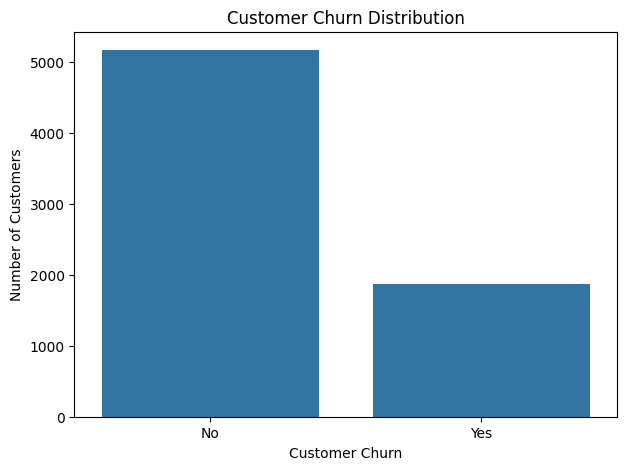

In [30]:
# visualizing the dataset
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [31]:
# Churn Rate By Contracte Rate
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


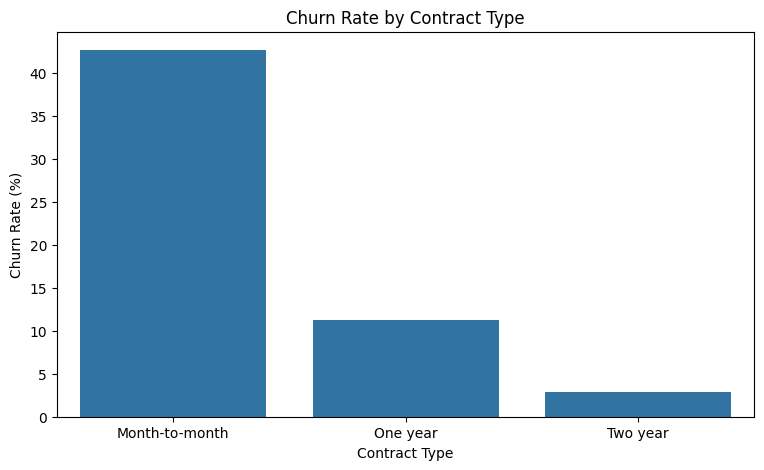

In [32]:
#visualizing the dataset by using graph
plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

# Customer Rate by Tenure

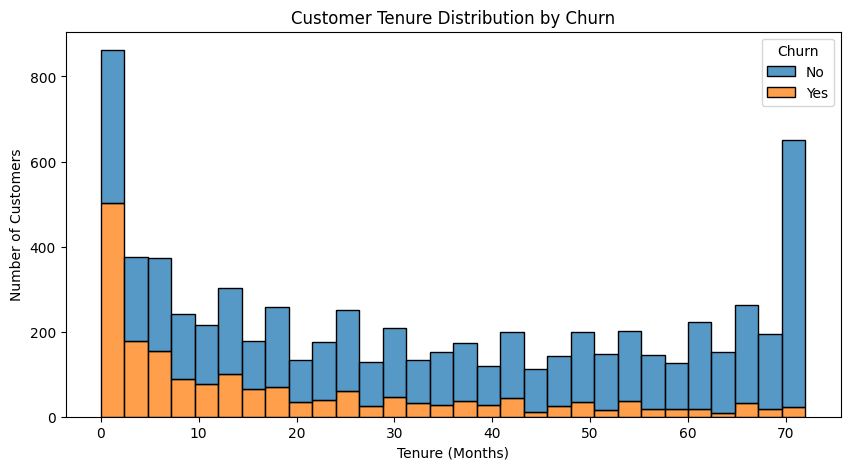

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [34]:
# Dividing the tenure in group 
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

In [35]:
#Group-wise churn:
tenure_churn = (
    df.groupby(
        "TenureGroup",
        observed=False
    )["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(tenure_churn)

TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Churn, dtype: float64


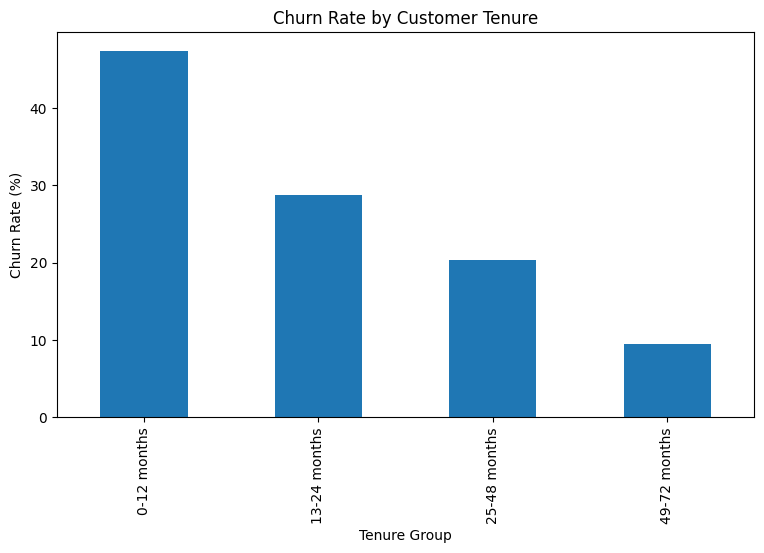

In [36]:
tenure_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

## Monthly charges vs churn

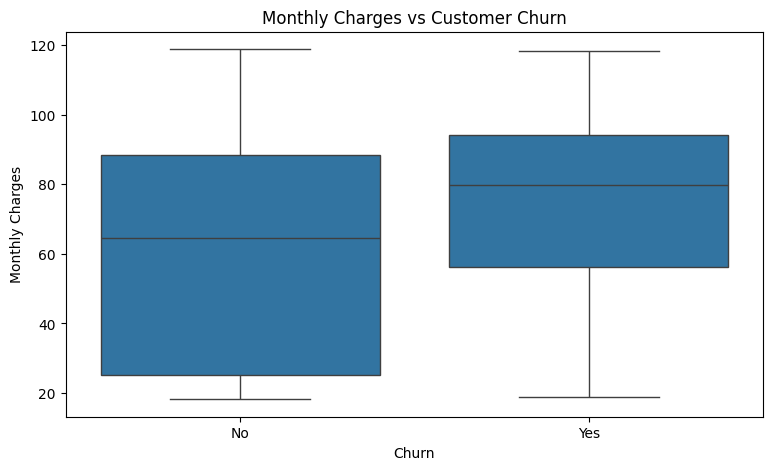

In [37]:
# checking the difference  in customer churned and customer retained in monthly charges
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [38]:
# Average monthly charges
monthly_charge_analysis = (
    df.groupby("Churn")["MonthlyCharges"]
    .mean()
)

print(monthly_charge_analysis)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [39]:
# Median monthly charges
print(
    df.groupby("Churn")["MonthlyCharges"].median()
)

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


## ANALYSIS THE CATEGORICAL FEATURE IN CUSTOMER CHURN DATASET

In [40]:
# creating the function for categorical feature to create churn rate

In [41]:
def calculate_churn_rate(data, column):

    result = (
        data.groupby(column, dropna=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    return result

In [42]:
calculate_churn_rate(
    df,
    "InternetService"
)

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

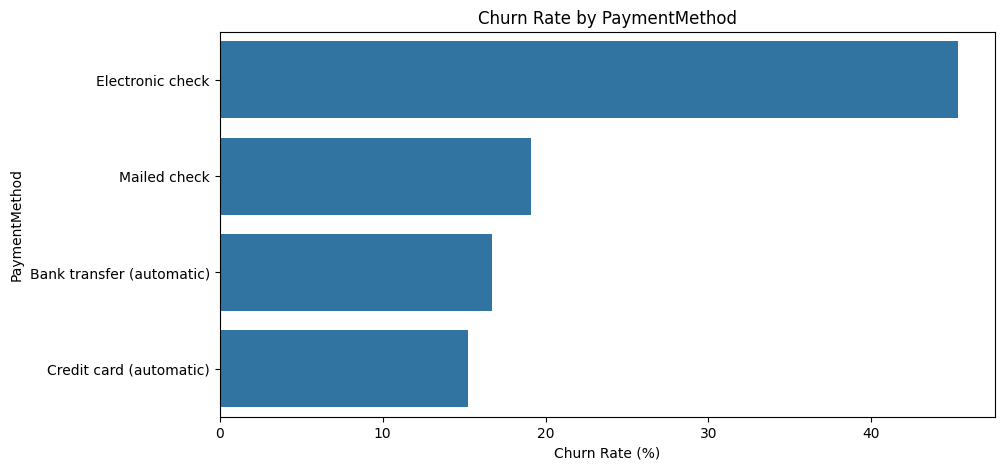

In [43]:
# Visualizing the dataset
column = "PaymentMethod"

result = calculate_churn_rate(df, column)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=result.values,
    y=result.index
)

plt.title(f"Churn Rate by {column}")
plt.xlabel("Churn Rate (%)")
plt.ylabel(column)

plt.show()

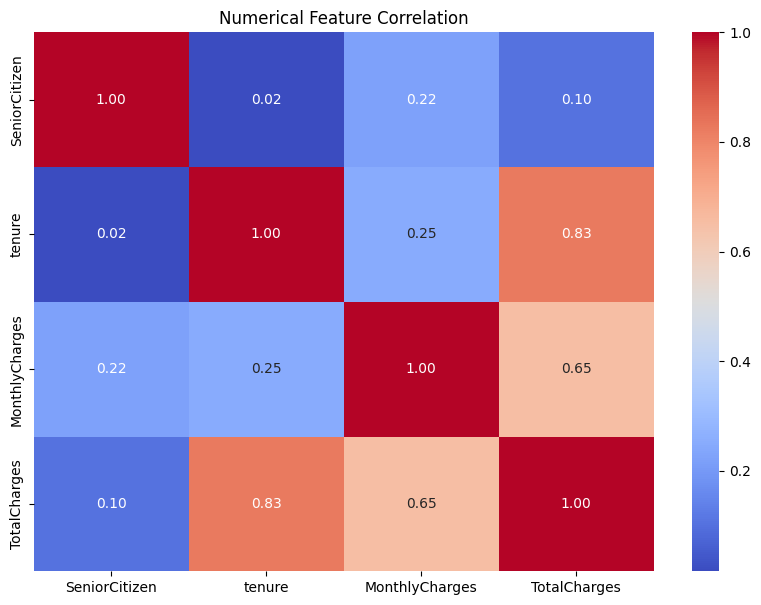

In [44]:
# correlation Matrix
numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.show()

## Save the clean dataset

In [45]:
import os

os.makedirs(
    "../data/processed",
    exist_ok=True
)

df.to_csv(
    "../data/processed/telco_churn_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## identify the target

In [46]:
target = "Churn"

X = df.drop(
    columns=[target, "customerID"],
    errors="ignore"
)

y = df[target]

In [47]:
# check the target variable 
print("Features:", X.shape)

print("Target:", y.shape)

print("Feature columns:")
print(X.columns.tolist())

Features: (7043, 20)
Target: (7043,)
Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup']


In [48]:
# Encode the target variable
print(y.value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [49]:
# convert the target variable into numerical variable
y = y.map({
    "No": 0,
    "Yes": 1
})

In [50]:
# verify the target variable
print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


## Performing the Feature Engineering

In [51]:
# Dividing the customer tenure into different group
X["TenureGroup"] = pd.cut(
    X["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New Customer",
        "Early Customer",
        "Established Customer",
        "Loyal Customer"
    ]
)

In [52]:
X[["tenure", "TenureGroup"]].head(10)

,tenure,TenureGroup
0,1,New Customer
1,34,Established Customer
2,2,New Customer
3,45,Established Customer
4,2,New Customer
5,8,New Customer
6,22,Early Customer
7,10,New Customer
8,28,Established Customer
9,62,Loyal Customer


In [53]:
# Monthly charges category 
X["ChargeCategory"] = pd.cut(
    X["MonthlyCharges"],
    bins=[0, 35, 70, 120],
    labels=[
        "Low Charges",
        "Medium Charges",
        "High Charges"
    ],
    include_lowest=True
)

In [54]:
X[["MonthlyCharges", "ChargeCategory"]].head(10)

,MonthlyCharges,ChargeCategory
0,29.85,Low Charges
1,56.95,Medium Charges
2,53.85,Medium Charges
3,42.30,Medium Charges
4,70.70,High Charges
5,99.65,High Charges
6,89.10,High Charges
7,29.75,Low Charges
8,104.80,High Charges
9,56.15,Medium Charges


In [55]:
print("Churn in X:", "Churn" in X.columns)

Churn in X: False


## Train Test Splits

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [57]:
# verify the train test split
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 21)
X_test: (1409, 21)
y_train: (5634,)
y_test: (1409,)


In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [59]:
# Identify feature types
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'ChargeCategory']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## Preprocessing the dataset

In [60]:
# Numerical pipeline
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [61]:
# Categorical pipeline
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])


In [62]:
# Combine both
preprocessor = ColumnTransformer([
    (
        "num",
        numerical_pipeline,
        numerical_features
    ),
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

## checking the preprocessing step

In [63]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

In [64]:
print(
    "Training data shape:",
    X_train_processed.shape
)

print(
    "Testing data shape:",
    X_test_processed.shape
)

Training data shape: (5634, 52)
Testing data shape: (1409, 52)


## ML preparation validation

In [65]:
print("========== ML PREPARATION REPORT ==========")

print("Total records:", len(df))

print("Total input features:", X.shape[1])

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("Missing values:", X.isnull().sum().sum())

print("Target values:", y.unique())

print("Churn rate in training:")
print(y_train.mean() * 100)

print("Churn rate in testing:")
print(y_test.mean() * 100)

print("Processed training shape:")
print(X_train_processed.shape)

print("Processed testing shape:")
print(X_test_processed.shape)

========== ML PREPARATION REPORT ==========
Total records: 7043
Total input features: 21
Training records: 5634
Testing records: 1409
Missing values: 0
Target values: [0 1]
Churn rate in training:
26.53532126375577
Churn rate in testing:
26.54364797728886
Processed training shape:
(5634, 52)
Processed testing shape:
(1409, 52)


## MODEL TRAIN

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in models.items():
    # Model training
    model.fit(X_train_processed, y_train)

    # Class predictions: 0 = No churn, 1 = Churn
    y_pred = model.predict(X_test_processed)

    # Probability of churn (class 1)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n========== {name} ==========")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))


========== Logistic Regression ==========
Confusion Matrix:
[[736 299]
 [ 76 298]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1035
       Churn       0.50      0.80      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.73      0.75      1409


========== Decision Tree ==========
Confusion Matrix:
[[780 255]
 [ 91 283]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409


========== Random Forest ==========
Confusion Matrix:
[[817 218]
 [103 271]]

Classification Report:
              precision    recall 

In [68]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.734,0.499,0.797,0.614,0.842
2,Random Forest,0.772,0.554,0.725,0.628,0.840
1,Decision Tree,0.754,0.526,0.757,0.621,0.832


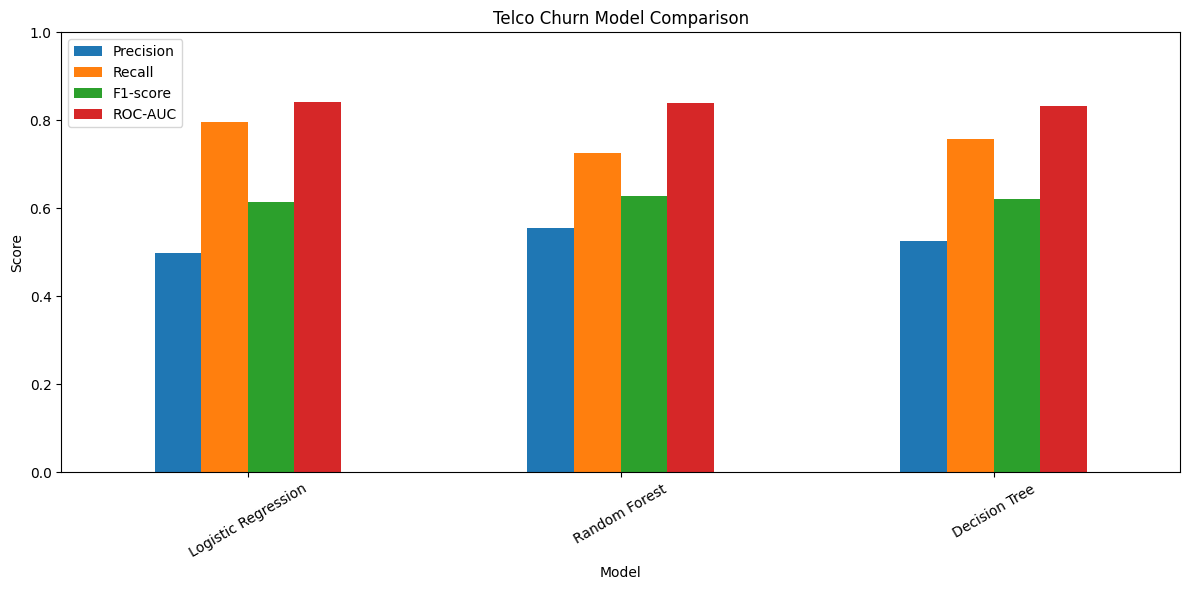

In [69]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Telco Churn Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## REMOVING THE CHURN PROBABILITY FROM MODEL

In [70]:
best_model = models["Random Forest"]

# Probability of Churn = Yes
y_prob = best_model.predict_proba(X_test_processed)[:, 1]

print(y_prob[:10])

[0.02043705 0.84289781 0.12689051 0.40269247 0.02613335 0.75305607
 0.50139218 0.13757352 0.00306762 0.52094323]


## ROC curve aur ROC-AUC

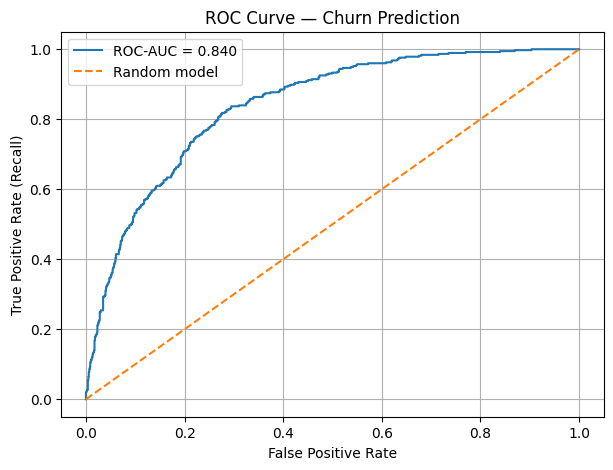

In [71]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Churn Prediction")
plt.legend()
plt.grid()
plt.show()

## Threshold tuning

In [72]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds_to_test = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds_to_test:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.2,0.412,0.920,0.570,490,30,344,545
1,0.3,0.470,0.864,0.609,364,51,323,671
2,0.4,0.519,0.799,0.629,277,75,299,758
3,0.5,0.554,0.725,0.628,218,103,271,817
4,0.6,0.607,0.607,0.607,147,147,227,888
5,0.7,0.679,0.487,0.567,86,192,182,949


## VISUALIZATION OF ROC CURVE 

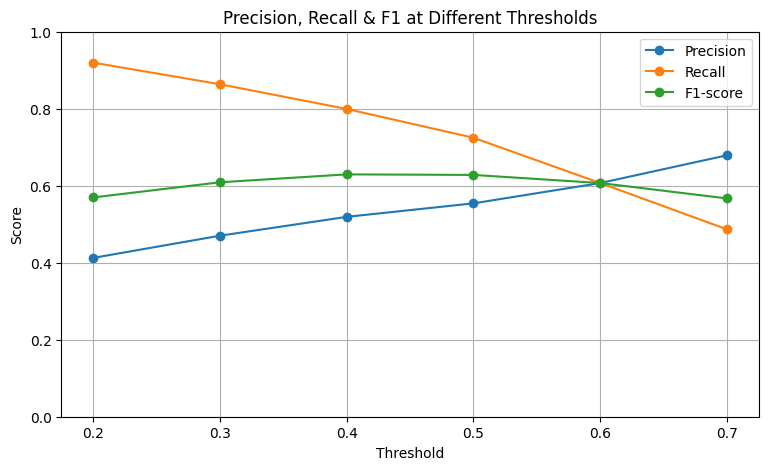

In [73]:
threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-score"]
].plot(marker="o", figsize=(9, 5))

plt.title("Precision, Recall & F1 at Different Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid()
plt.show()

In [74]:
risk_df = pd.DataFrame({
    "Actual_Churn": y_test,
    "Churn_Probability": y_prob
})

risk_df["Risk_Level"] = pd.cut(
    risk_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

risk_df.head(10)

,Actual_Churn,Churn_Probability,Risk_Level
437,0,0.020437,Low Risk
2280,0,0.842898,High Risk
2235,0,0.126891,Low Risk
4460,0,0.402692,Medium Risk
3761,0,0.026133,Low Risk
5748,0,0.753056,High Risk
3568,0,0.501392,Medium Risk
2976,0,0.137574,Low Risk
5928,0,0.003068,Low Risk
1639,1,0.520943,Medium Risk


In [75]:
risk_df["Risk_Level"].value_counts()

Risk_Level
Low Risk       722
High Risk      374
Medium Risk    313
Name: count, dtype: int64

In [76]:
risk_df.groupby("Risk_Level", observed=False).agg(
    Customers=("Actual_Churn", "count"),
    Actual_Churners=("Actual_Churn", "sum"),
    Average_Churn_Probability=("Churn_Probability", "mean")
).round(3)

,Customers,Actual_Churners,Average_Churn_Probability
Risk_Level,,,
Low Risk,722,51,0.109
Medium Risk,313,96,0.450
High Risk,374,227,0.768


## Feature importance — Random Forest

In [77]:
best_model = models["Random Forest"]

import pandas as pd

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
1,num__tenure,0.112062
36,cat__Contract_Month-to-month,0.096109
3,num__TotalCharges,0.092556
2,num__MonthlyCharges,0.073128
27,cat__TechSupport_No,0.059941
38,cat__Contract_Two year,0.049848
18,cat__OnlineSecurity_No,0.045051
16,cat__InternetService_Fiber optic,0.037336
48,cat__TenureGroup_New Customer,0.035451
43,cat__PaymentMethod_Electronic check,0.033942


## Top 15 features ka chart

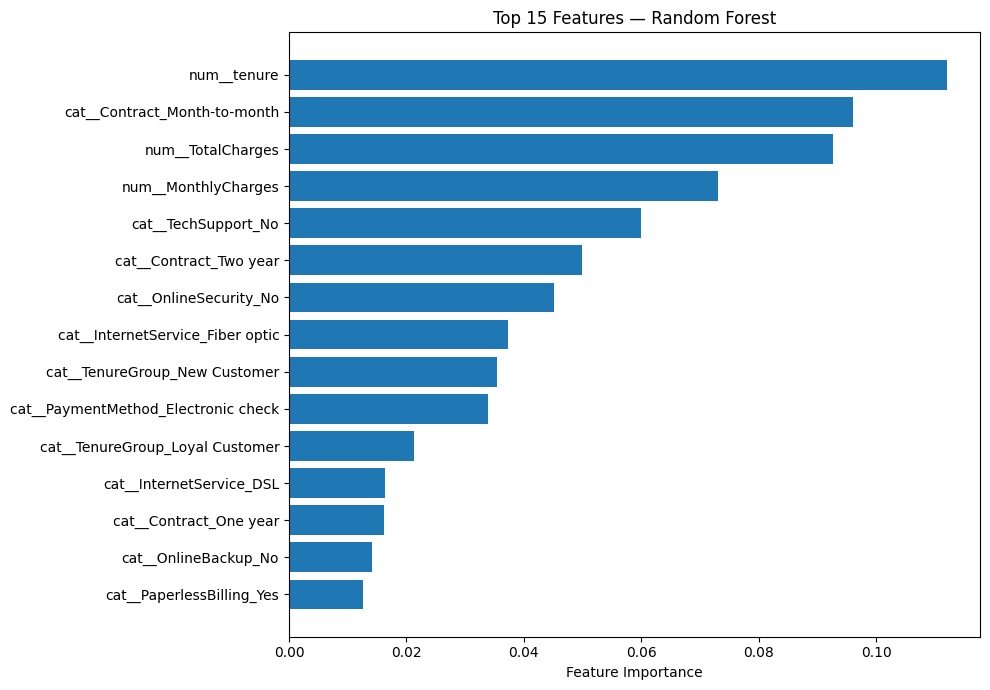

In [78]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Feature Importance")
plt.title("Top 15 Features — Random Forest")
plt.tight_layout()
plt.show()

In [79]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_test_processed,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

permutation_df.head(15)

,Feature,Importance_Mean,Importance_Std
36,cat__Contract_Month-to-month,0.021502,0.002856
1,num__tenure,0.017956,0.001179
3,num__TotalCharges,0.006779,0.000668
38,cat__Contract_Two year,0.006699,0.001133
27,cat__TechSupport_No,0.004454,0.000798
16,cat__InternetService_Fiber optic,0.003562,0.003424
48,cat__TenureGroup_New Customer,0.003401,0.000500
47,cat__TenureGroup_Loyal Customer,0.001160,0.000404
15,cat__InternetService_DSL,0.000997,0.002711
18,cat__OnlineSecurity_No,0.000720,0.001893


top_perm = permutation_df.head(15).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_perm["Feature"],
    top_perm["Importance_Mean"],
    xerr=top_perm["Importance_Std"]
)

plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.title("Permutation Importance — Top 15")
plt.tight_layout()
plt.show()

## Customer churn patterns ko data se verify IT

In [80]:
df["Churn_Flag"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

contract_churn = (
    df.groupby("Contract", observed=False)["Churn_Flag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

contract_churn

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn_Flag, dtype: float64

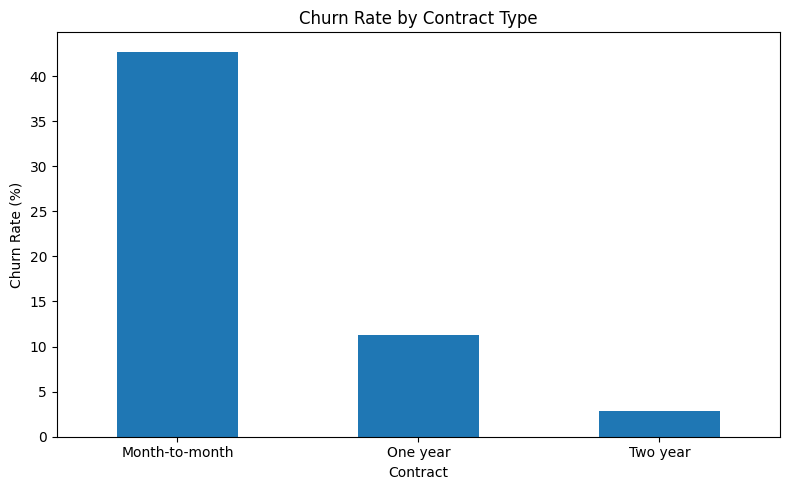

In [81]:
contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Contract Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [82]:
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn_Flag"]
      .mean()
      .mul(100)
)

tenure_churn

TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Churn_Flag, dtype: float64

In [83]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New Customer",
        "Early Customer",
        "Established Customer",
        "Loyal Customer"
    ]
)

## High-risk customers ke liye actionable list

In [84]:
high_risk_customers = X_test.copy()

high_risk_customers["Churn_Probability"] = y_prob
high_risk_customers["Risk_Level"] = pd.cut(
    high_risk_customers["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

high_risk_customers = high_risk_customers[
    high_risk_customers["Risk_Level"] == "High Risk"
]

high_risk_customers.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureGroup,ChargeCategory,Churn_Probability,Risk_Level
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,New Customer,High Charges,0.842898,High Risk
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,Early Customer,High Charges,0.753056,High Risk
3524,Female,1,No,No,11,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),84.80,906.85,New Customer,High Charges,0.796158,High Risk
2136,Male,0,No,Yes,15,Yes,Yes,Fiber optic,No,Yes,...,No,Month-to-month,Yes,Electronic check,91.00,1430.05,Early Customer,High Charges,0.773237,High Risk
6529,Male,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Mailed check,74.85,156.40,New Customer,High Charges,0.864266,High Risk


In [85]:
%pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [86]:
from xgboost import XGBClassifier

# Churn=1 minority class ho sakti hai
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost training complete.")

XGBoost training complete.


## Comparing the xgboost with other model

In [87]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

all_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest": models["Random Forest"],
    "XGBoost": xgb_model
}

comparison = []

for name, model in all_models.items():
    pred = model.predict(X_test_processed)
    prob = model.predict_proba(X_test_processed)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.sort_values("ROC_AUC", ascending=False).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
3,XGBoost,0.757,0.529,0.778,0.630,0.844
0,Logistic Regression,0.734,0.499,0.797,0.614,0.842
2,Random Forest,0.772,0.554,0.725,0.628,0.840
1,Decision Tree,0.754,0.526,0.757,0.621,0.832


## Training data se validation set banao

In [88]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Subtrain:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Validation churn rate:", round(y_val.mean(), 3))

Subtrain: (4507, 52)
Validation: (1127, 52)
Validation churn rate: 0.265


In [89]:
xgb_model.fit(X_subtrain, y_subtrain)

val_prob = xgb_model.predict_proba(X_val)[:, 1]

## choosing the threshold on validation

In [90]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
val_results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1]
    ).ravel()

    val_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "False_Positive": fp,
        "False_Negative": fn
    })

val_threshold_df = pd.DataFrame(val_results)
val_threshold_df.round(3)

,Threshold,Precision,Recall,F1,False_Positive,False_Negative
0,0.3,0.454,0.893,0.602,321,32
1,0.4,0.495,0.829,0.620,253,51
2,0.5,0.536,0.776,0.634,201,67
3,0.6,0.597,0.702,0.645,142,89
4,0.7,0.664,0.535,0.593,81,139


## Chosen threshold ko test set par final evaluate karo

In [91]:
chosen_threshold = 0.60  # Validation result ke basis par update karo

test_prob = xgb_model.predict_proba(X_test_processed)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

print("Chosen threshold:", chosen_threshold)
print("Test Precision:", precision_score(
    y_test, test_pred, zero_division=0
))
print("Test Recall:", recall_score(
    y_test, test_pred, zero_division=0
))
print("Test F1:", f1_score(
    y_test, test_pred, zero_division=0
))
print("Test ROC-AUC:", roc_auc_score(y_test, test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Chosen threshold: 0.6
Test Precision: 0.56
Test Recall: 0.6737967914438503
Test F1: 0.6116504854368932
Test ROC-AUC: 0.8391356015396938

Confusion Matrix:
[[837 198]
 [122 252]]


In [92]:
import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Class imbalance calculate karo
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

if positive_count == 0:
    raise ValueError("Training data mein Churn=1 class nahi hai.")

scale_pos_weight = negative_count / positive_count

# XGBoost model
final_xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Preprocessing + Model ko ek pipeline mein combine karo
churn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", final_xgb_model)
    ]
)

# Raw training data par pipeline train karo
churn_pipeline.fit(X_train, y_train)

print("Reusable churn pipeline trained successfully!")

Reusable churn pipeline trained successfully!


In [93]:
# Threshold ko apne validation result ke mutabiq set karo
chosen_threshold = 0.60

# Training ke waqt use hue original columns
feature_columns = X_train.columns.tolist()

# Model bundle
model_bundle = {
    "pipeline": churn_pipeline,
    "threshold": chosen_threshold,
    "feature_columns": feature_columns,
    "risk_bins": [0.0, 0.30, 0.60, 1.0],
    "risk_labels": ["Low Risk", "Medium Risk", "High Risk"]
}

# Save model
joblib.dump(
    model_bundle,
    "telco_churn_pipeline.joblib"
)

print("Model saved successfully!")
print("File: telco_churn_pipeline.joblib")

Model saved successfully!
File: telco_churn_pipeline.joblib


In [94]:
import joblib
import pandas as pd
import numpy as np

# Saved model load karo
loaded_bundle = joblib.load("telco_churn_pipeline.joblib")

loaded_pipeline = loaded_bundle["pipeline"]
loaded_threshold = loaded_bundle["threshold"]
loaded_features = loaded_bundle["feature_columns"]

print("Saved model loaded successfully!")
print("Prediction threshold:", loaded_threshold)

Saved model loaded successfully!
Prediction threshold: 0.6


In [103]:
import pandas as pd
import numpy as np

def predict_customer_churn(customer):

    # Step 1: Convert input into DataFrame
    if isinstance(customer, pd.DataFrame):
        customer_df = customer.copy()

    elif isinstance(customer, pd.Series):
        customer_df = customer.to_frame().T

    elif isinstance(customer, dict):
        customer_df = pd.DataFrame([customer])

    else:
        raise TypeError(
            "Input must be DataFrame, Series, or dictionary"
        )

    # Step 2: Check missing features
    missing_features = [
        col for col in loaded_features
        if col not in customer_df.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # Step 3: Arrange features in correct order
    customer_df = customer_df[loaded_features]

    # Step 4: Predict churn probability
    churn_probability = loaded_pipeline.predict_proba(
        customer_df
    )[:, 1]

    # Step 5: Apply saved threshold
    prediction = (
        churn_probability >= loaded_threshold
    ).astype(int)

    # Step 6: Calculate risk level
    risk_level = pd.cut(
        churn_probability,
        bins=loaded_bundle["risk_bins"],
        labels=loaded_bundle["risk_labels"],
        include_lowest=True
    )

    # Step 7: Create result DataFrame
    result = pd.DataFrame({
        "Churn_Probability": churn_probability,
        "Prediction": prediction,
        "Risk_Level": risk_level
    })

    return result

In [104]:
# Select one customer from X_test
sample_customer = X_test.iloc[[0]]

# Predict customer churn
prediction_result = predict_customer_churn(
    sample_customer
)

# Display prediction result
prediction_result

,Churn_Probability,Prediction,Risk_Level
0,0.012544,0,Low Risk


In [105]:
result = prediction_result.iloc[0]

print("=" * 40)
print("CUSTOMER CHURN ANALYSIS")
print("=" * 40)

print(
    f"Churn Probability: "
    f"{result['Churn_Probability']:.2%}"
)

print(
    f"Prediction: "
    f"{'Churn' if result['Prediction'] == 1 else 'No Churn'}"
)

print(f"Risk Level: {result['Risk_Level']}")

print("=" * 40)

CUSTOMER CHURN ANALYSIS
Churn Probability: 1.25%
Prediction: No Churn
Risk Level: Low Risk


In [106]:
# X_test ke ek customer ko dictionary mein convert karo
customer_dict = X_test.iloc[0].to_dict()

# Prediction
result = predict_customer_churn(customer_dict)

print("Churn Probability:",
      round(result["Churn_Probability"].iloc[0] * 100, 2), "%")

print("Prediction:",
      result["Prediction"].iloc[0])

print("Risk Level:",
      result["Risk_Level"].iloc[0])

Churn Probability: 1.25 %
Prediction: 0
Risk Level: Low Risk


In [107]:
import joblib

# Model ko file se dobara load karo
saved_bundle = joblib.load(
    "telco_churn_pipeline.joblib"
)

saved_pipeline = saved_bundle["pipeline"]

# Loaded model se probability
saved_probability = saved_pipeline.predict_proba(
    X_test.iloc[[0]]
)[:, 1][0]

print("Loaded Model Churn Probability:",
      round(saved_probability, 4))

Loaded Model Churn Probability: 0.0125
